In [1]:
import contextily as cx
import geopandas as gpd
import pandas as pd

In [2]:
aws_ts_df_filepath = "../data/interim/aws-ts-df.csv"
lcs_ts_df_filepath = "../data/interim/lcs-ts-df.csv"

aws_stations_gdf_filepath = "../data/interim/aws-stations.gpkg"
lcs_stations_gdf_filepath = "../data/interim/lcs-stations.gpkg"

stations_crs = "epsg:2056"
source_labels = ["AWS", "LCS"]

dst_station_id_col = "station_id"
dst_stations_gdf_filepath = "../data/processed/stations.gpkg"
dst_ts_df_filepath = "../data/processed/ts-df.csv"

In [3]:
# Parameters
aws_ts_df_filepath = "data/interim/aws-ts-df.csv"
lcs_ts_df_filepath = "data/interim/lcs-ts-df.csv"
aws_stations_gdf_filepath = "data/interim/aws-stations.gpkg"
lcs_stations_gdf_filepath = "data/interim/lcs-stations.gpkg"
dst_ts_df_filepath = "data/processed/ts-df.csv"
dst_stations_gdf_filepath = "data/processed/stations.gpkg"


In [4]:
# merge both data sources: resample each to hourly and concatenate along columns
ts_df = pd.concat(
    [
        pd.concat(
            [
                heatwave_ts_df.loc[heatwave]
                .resample("h")
                .mean()
                .assign(**{"heatwave": heatwave})
                for heatwave, heatwave_ts_df in pd.read_csv(
                    ts_df_filepath,
                    index_col=["heatwave", "time"],
                    parse_dates=["time"],
                ).groupby("heatwave")
            ],
            axis="rows",
        )
        for ts_df_filepath in [aws_ts_df_filepath, lcs_ts_df_filepath]
    ],
    axis="columns",
)
# deduplicate heatwave column from the two sources, restore MultiIndex
ts_df = (
    ts_df.loc[:, ~ts_df.columns.duplicated()]
    .reset_index()
    .set_index(["heatwave", "time"])
)
ts_df

REH        SMA  \
heatwave              time                                        
2022-06-15/2022-06-20 2022-06-15 00:00:00  12.616667  15.616667   
                      2022-06-15 01:00:00  12.450000  15.033333   
                      2022-06-15 02:00:00  12.600000  15.383333   
                      2022-06-15 03:00:00  13.150000  15.883333   
                      2022-06-15 04:00:00  13.466667  15.833333   
...                                              ...        ...   
2025-08-08/2025-08-16 2025-08-16 19:00:00  24.083333  23.600000   
                      2025-08-16 20:00:00  23.333333  22.583333   
                      2025-08-16 21:00:00  22.850000  21.916667   
                      2025-08-16 22:00:00  21.333333  21.000000   
                      2025-08-16 23:00:00  19.916667  20.283333   

                                           Zürich-Kaserne  Dübendorf-Empa  \
heatwave              time                                                  
2022-06-15/2022-06-20 2022-06-15 00:00:00            19.0            14.5   
                      2022-06-15 01:00:00            18.2            13.9   
                      2022-06-15 02:00:00            17.8            14.0   
                      2022-06-15 03:00:00            17.6            14.3   
                      2022-06-15 04:00:00            17.6            15.0   
...                                                   ...             ...   
2025-08-08/2025-08-16 2025-08-16 19:00:00            26.0            24.5   
                      2025-08-16 20:00:00            24.9            23.5   
                      2025-08-16 21:00:00            24.3            22.9   
                      2025-08-16 22:00:00            23.7            21.5   
                      2025-08-16 23:00:00            22.8            20.3   

                                              A10      A7  B12      B3  \
heatwave              time                                               
2022-06-15/2022-06-20 2022-06-15 00:00:00     NaN     NaN  NaN  17.650   
                      2022-06-15 01:00:00     NaN     NaN  NaN  16.550   
                      2022-06-15 02:00:00     NaN     NaN  NaN  15.875   
                      2022-06-15 03:00:00     NaN     NaN  NaN  15.900   
                      2022-06-15 04:00:00     NaN     NaN  NaN  15.725   
...                                           ...     ...  ...     ...   
2025-08-08/2025-08-16 2025-08-16 19:00:00  22.675  25.850  NaN  25.150   
                      2025-08-16 20:00:00  22.700  24.975  NaN  24.250   
                      2025-08-16 21:00:00  22.625  24.400  NaN  23.675   
                      2025-08-16 22:00:00  21.275  23.575  NaN  23.000   
                      2025-08-16 23:00:00  20.300  22.175  NaN  21.750   

                                               B6     B9  ...       2692  \
heatwave              time                                ...              
2022-06-15/2022-06-20 2022-06-15 00:00:00  15.225    NaN  ...  19.116667   
                      2022-06-15 01:00:00  14.550    NaN  ...  18.515000   
                      2022-06-15 02:00:00  14.875    NaN  ...  17.921667   
                      2022-06-15 03:00:00  15.250    NaN  ...  17.721667   
                      2022-06-15 04:00:00  15.925    NaN  ...  17.713333   
...                                           ...    ...  ...        ...   
2025-08-08/2025-08-16 2025-08-16 19:00:00  25.700  27.65  ...        NaN   
                      2025-08-16 20:00:00  24.850    NaN  ...        NaN   
                      2025-08-16 21:00:00  24.425    NaN  ...        NaN   
                      2025-08-16 22:00:00  23.575    NaN  ...        NaN   
                      2025-08-16 23:00:00  22.300  24.40  ...        NaN   

                                                2695       2696       2697  \
heatwave              time                                                   
2022-06-15/2022-06-20 2022-06-15 00:00:00  18.048333  16.223333  15

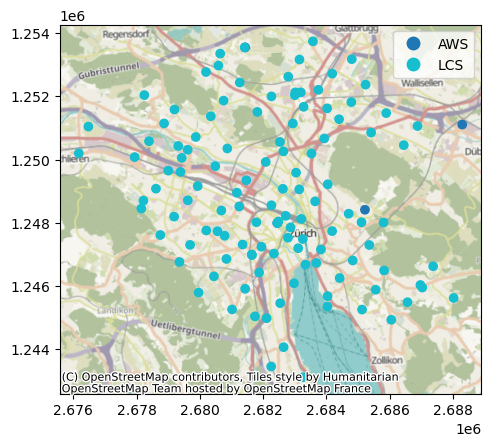

In [5]:
stations_gdf = (
    pd.concat(
        [
            gpd.read_file(stations_gdf_filepath)
            .to_crs(stations_crs)
            .rename(columns={"index": dst_station_id_col})[
                [dst_station_id_col, "geometry"]
            ]
            .assign(source=source)
            for stations_gdf_filepath, source in zip(
                [aws_stations_gdf_filepath, lcs_stations_gdf_filepath],
                source_labels,
            )
        ]
    )
    .set_index(dst_station_id_col)
    .loc[ts_df.columns]
    .reset_index(names=dst_station_id_col)
)
ax = stations_gdf.plot("source", legend=True)
cx.add_basemap(ax, crs=stations_gdf.crs)

In [6]:
stations_gdf["source"].value_counts()

source
LCS    118
AWS      4
Name: count, dtype: int64

In [7]:
ts_df.to_csv(dst_ts_df_filepath)
stations_gdf.to_file(dst_stations_gdf_filepath)